# Which Fraud-Detection Strategy Works Best Under Severe Class Imbalance?

**ESE 5420 baseline checkpoint** — logistic regression under severe class imbalance.

**Question (sharpened):** which repair gives the lowest expected cost at `c_FN / c_FP = 10` and `100` for logistic regression (histogram gradient boosting comes later)?

This notebook:
1. Loads OpenML CreditCardFraudDetection (ID 42175) from `data/creditcard.csv`
2. **Drops exact duplicate rows** (this dataset contains duplicate transactions; left in place they can leak across the train/test or CV split)
3. Replaces raw `Time` with `Time_of_day = Time % 86400`
4. Holds out a stratified 20% test set (seed 42) — **unused until final evaluation**
5. Tunes L2 logistic regression `C` by mean Average Precision in stratified 5-fold CV
6. Compares four strategies on fold metrics: no repair (0.5), formula τ*, CV-chosen τ, and `class_weight='balanced'`
7. Reports a fold-level standard error / 95% CI alongside the fold min/max
8. Saves `results/baseline.png`, `results/baseline_results.json`, and `results/baseline_folds.csv`

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path(".").resolve()
DATA_CSV = ROOT / "data" / "creditcard.csv"
RESULTS_DIR = ROOT / "results"
DATA_CSV.parent.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_FOLDS = 5
C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
COST_RATIOS = [10, 100]  # c_FN / c_FP
THRESHOLD_GRID = np.unique(
    np.concatenate([
        np.array([0.5]),
        np.array([1.0 / (1.0 + r) for r in COST_RATIOS]),
        np.geomspace(1e-4, 0.5, 40),
    ])
)

print(f"Project root: {ROOT}")

Project root: .


## 1. Load data, drop exact duplicates

Prefer the local CSV so reruns are offline. If missing, fetch OpenML ID 42175 and cache it.

This dataset is known to contain exact duplicate transactions (identical `Time`, `Amount`,
`V1`–`V28`, and `Class`). Left in place, a random train/test or CV split can put one copy of
a duplicate pair in training and its twin in validation/test — leaking that exact row into
evaluation and inflating recall/AP for a model that has effectively already seen it. We drop
duplicates immediately after loading, before any split.

In [2]:
if DATA_CSV.exists():
    print(f"Loading local CSV: {DATA_CSV}")
    df = pd.read_csv(DATA_CSV)
else:
    print("Fetching OpenML CreditCardFraudDetection (ID 42175)...")
    ds = fetch_openml(data_id=42175, as_frame=True, parser="auto")
    df = ds.data.copy()
    df["Class"] = ds.target.astype(int)
    for c in df.columns:
        if c != "Class":
            df[c] = df[c].astype(float)
    df["Class"] = df["Class"].astype(int)
    df.to_csv(DATA_CSV, index=False)
    print(f"Saved {DATA_CSV}")

assert set(["Time", "Amount", "Class"]).issubset(df.columns)
assert df.isna().sum().sum() == 0

n_before = len(df)
frauds_before = int(df["Class"].sum())
dup_mask = df.duplicated()
n_dupes = int(dup_mask.sum())
dupe_frauds = int(df.loc[dup_mask, "Class"].sum())
df = df.drop_duplicates().reset_index(drop=True)

y_all = df["Class"].astype(int).to_numpy()
print(
    f"Dropped {n_dupes} exact duplicate rows ({dupe_frauds} of them fraud) "
    f"out of {n_before} rows (was {frauds_before} frauds)."
)
print(
    f"N = {len(df)}, inputs = {df.shape[1] - 1}, "
    f"frauds = {int(y_all.sum())} ({y_all.mean() * 100:.3f}%)"
)

Loading local CSV: .\data\creditcard.csv


Dropped 1081 exact duplicate rows (19 of them fraud) out of 284807 rows (was 492 frauds).
N = 283726, inputs = 30, frauds = 473 (0.167%)


## 2. Features and split

Raw `Time` is seconds since the first transaction in a two-day file. With a random split that
leaks which part of the file a row came from. We replace it with **time of day**
(`Time % 86400`) and keep `Amount` and `V1`–`V28`.

Stratified 80/20, `random_state=42`. The test set is set aside and not used in this checkpoint.

In [3]:
X = df.drop(columns=["Class"]).astype(float).copy()
X["Time_of_day"] = X["Time"] % 86400.0
X = X.drop(columns=["Time"])
y = df["Class"].astype(int).to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Features ({X_train.shape[1]}): {list(X_train.columns)}")
print(f"Train: n={len(y_train)}, frauds={int(y_train.sum())}")
print(f"Test : n={len(y_test)},  frauds={int(y_test.sum())}  (held out, unused here)")
del X_test, y_test  # keep the split reproducible but do not peek

Features (30): ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Time_of_day']
Train: n=226980, frauds=378
Test : n=56746,  frauds=95  (held out, unused here)


## 3. Helpers

- Expected cost per transaction: `(c_FP * FP + c_FN * FN) / n` with `c_FP = 1`, `c_FN = ratio`.
- Formula threshold: `τ* = c_FP / (c_FP + c_FN) = 1 / (1 + ratio)`.
- CV-chosen threshold: minimize training-fold cost on a threshold grid, then score the
  validation fold (honest fold cost). *Caveat:* the threshold itself is picked using
  in-sample training-fold probabilities, not a nested inner split — the reported **cost**
  is still honestly computed on the held-out validation fold, but the chosen τ is a mildly
  optimistic point estimate.
- `summarize_metric`: mean, fold min/max, **and** a fold-level standard error / 95% CI
  (`t`-distribution, df = K-1). This SE describes how much the mean would move if CV were
  rerun with a different fold split — it is a different, complementary quantity to the
  paired bootstrap CI planned later for the held-out test set (which captures per-transaction
  noise, important given only 98 test frauds).

In [4]:
def expected_cost(y_true, proba, ratio, threshold=0.5, c_fp=1.0):
    c_fn = c_fp * ratio
    pred = (proba >= threshold).astype(int)
    fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())
    return (c_fp * fp + c_fn * fn) / len(y_true)


def formula_threshold(ratio: float) -> float:
    return 1.0 / (1.0 + ratio)


def choose_threshold(y_true, proba, ratio, grid=THRESHOLD_GRID):
    costs = [expected_cost(y_true, proba, ratio, t) for t in grid]
    return float(grid[int(np.argmin(costs))])


def make_lr(C: float, class_weight=None) -> Pipeline:
    return Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(
            C=C,
            penalty="l2",
            solver="lbfgs",
            max_iter=2000,
            class_weight=class_weight,
            random_state=RANDOM_STATE,
        )),
    ])


def summarize_metric(df: pd.DataFrame, col: str) -> dict:
    vals = df[col].to_numpy(dtype=float)
    k = len(vals)
    mean = float(vals.mean())
    lo, hi = float(vals.min()), float(vals.max())
    se = float(vals.std(ddof=1) / np.sqrt(k)) if k > 1 else 0.0
    t_crit = float(stats.t.ppf(0.975, df=k - 1)) if k > 1 else float("nan")
    half = t_crit * se
    return {"mean": mean, "min": lo, "max": hi, "se": se,
            "ci95_lo": mean - half, "ci95_hi": mean + half}

## 4. Tune `C` by Average Precision (no repair)

Cost at threshold 0.5 is nearly flat once `C ≥ 0.1`, so we select `C` by mean validation AP
(ranking quality). Scaling stays inside each training fold.

In [5]:
def collect_oof_proba(C, X_tr, y_tr, class_weight=None):
    """Fit in stratified 5-fold CV; return OOF probabilities and per-fold rows."""
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    oof = np.zeros(len(y_tr), dtype=float)
    fold_rows = []

    for fold_i, (tr, va) in enumerate(skf.split(X_tr, y_tr)):
        pipe = make_lr(C, class_weight=class_weight)
        pipe.fit(X_tr.iloc[tr], y_tr[tr])
        proba_tr = pipe.predict_proba(X_tr.iloc[tr])[:, 1]
        proba_va = pipe.predict_proba(X_tr.iloc[va])[:, 1]
        oof[va] = proba_va

        row = {
            "fold": fold_i,
            "C": C,
            "class_weight": "balanced" if class_weight == "balanced" else "none",
            "ap": average_precision_score(y_tr[va], proba_va),
            "precision@0.5": precision_score(
                y_tr[va], (proba_va >= 0.5).astype(int), zero_division=0),
            "recall@0.5": recall_score(
                y_tr[va], (proba_va >= 0.5).astype(int), zero_division=0),
        }

        for r in COST_RATIOS:
            tau_star = formula_threshold(r)
            tau_cv = choose_threshold(y_tr[tr], proba_tr, r)
            row[f"cost_norepair_r{r}"] = expected_cost(y_tr[va], proba_va, r, 0.5)
            row[f"cost_formula_r{r}"] = expected_cost(y_tr[va], proba_va, r, tau_star)
            row[f"cost_cvtau_r{r}"] = expected_cost(y_tr[va], proba_va, r, tau_cv)
            row[f"tau_formula_r{r}"] = tau_star
            row[f"tau_cv_r{r}"] = tau_cv
            row[f"precision_formula_r{r}"] = precision_score(
                y_tr[va], (proba_va >= tau_star).astype(int), zero_division=0)
            row[f"recall_formula_r{r}"] = recall_score(
                y_tr[va], (proba_va >= tau_star).astype(int), zero_division=0)
            row[f"precision_cvtau_r{r}"] = precision_score(
                y_tr[va], (proba_va >= tau_cv).astype(int), zero_division=0)
            row[f"recall_cvtau_r{r}"] = recall_score(
                y_tr[va], (proba_va >= tau_cv).astype(int), zero_division=0)

        fold_rows.append(row)

    return oof, pd.DataFrame(fold_rows)


print("Grid search over C (no repair) — select by mean AP...")
grid_rows = []
fold_tables = {}
for C in C_GRID:
    _, fold_df = collect_oof_proba(C, X_train, y_train, class_weight=None)
    mean_ap = fold_df["ap"].mean()
    mean_cost100 = fold_df["cost_norepair_r100"].mean()
    grid_rows.append({"C": C, "mean_ap": mean_ap, "mean_cost_r100@0.5": mean_cost100})
    fold_tables[C] = fold_df
    print(f"  C={C:>8g}  mean AP={mean_ap:.4f}  mean cost@0.5 (r=100)={mean_cost100:.6f}")

grid_df = pd.DataFrame(grid_rows)
best_C = float(grid_df.loc[grid_df["mean_ap"].idxmax(), "C"])
best_df = fold_tables[best_C]
ap_spread = grid_df["mean_ap"].max() - grid_df["mean_ap"].min()
print(f"\nSelected C = {best_C} (max mean AP)")
print(
    f"Note: mean AP ranges only {ap_spread:.4f} across the whole C grid (C >= 0.1 is a "
    "near-tie) — the argmax C is not stable across reruns/environments and should not be "
    "over-interpreted."
)
grid_df

Grid search over C (no repair) — select by mean AP...


  C=   0.001  mean AP=0.7507  mean cost@0.5 (r=100)=0.085602


  C=    0.01  mean AP=0.7540  mean cost@0.5 (r=100)=0.070627


  C=     0.1  mean AP=0.7563  mean cost@0.5 (r=100)=0.066248


  C=       1  mean AP=0.7538  mean cost@0.5 (r=100)=0.063609


  C=      10  mean AP=0.7534  mean cost@0.5 (r=100)=0.063609


  C=     100  mean AP=0.7533  mean cost@0.5 (r=100)=0.063609


  C=    1000  mean AP=0.7533  mean cost@0.5 (r=100)=0.063609

Selected C = 0.1 (max mean AP)
Note: mean AP ranges only 0.0056 across the whole C grid (C >= 0.1 is a near-tie) — the argmax C is not stable across reruns/environments and should not be over-interpreted.


,C,mean_ap,mean_cost_r100@0.5
0,0.001,0.750655,0.085602
1,0.010,0.753960,0.070627
2,0.100,0.756257,0.066248
3,1.000,0.753761,0.063609
4,10.000,0.753368,0.063609
5,100.000,0.753346,0.063609
6,1000.000,0.753331,0.063609


## 5. Class weights (`class_weight='balanced'`)

Retune `C` by AP under balanced class weights. Threshold stays at 0.5 so this repair is not
stacked with τ*.

In [6]:
print("Grid search over C (class_weight='balanced') — select by mean AP...")
bal_grid_rows = []
bal_fold_tables = {}
for C in C_GRID:
    _, fold_df = collect_oof_proba(C, X_train, y_train, class_weight="balanced")
    mean_ap = fold_df["ap"].mean()
    mean_cost100 = fold_df["cost_norepair_r100"].mean()
    bal_grid_rows.append({"C": C, "mean_ap": mean_ap, "mean_cost_r100@0.5": mean_cost100})
    bal_fold_tables[C] = fold_df
    print(f"  C={C:>8g}  mean AP={mean_ap:.4f}  mean cost@0.5 (r=100)={mean_cost100:.6f}")

bal_grid_df = pd.DataFrame(bal_grid_rows)
best_C_bal = float(bal_grid_df.loc[bal_grid_df["mean_ap"].idxmax(), "C"])
bal_df = bal_fold_tables[best_C_bal]
print(f"\nSelected C (balanced) = {best_C_bal}")
bal_grid_df

Grid search over C (class_weight='balanced') — select by mean AP...


  C=   0.001  mean AP=0.7359  mean cost@0.5 (r=100)=0.038840


  C=    0.01  mean AP=0.7352  mean cost@0.5 (r=100)=0.040219


  C=     0.1  mean AP=0.7406  mean cost@0.5 (r=100)=0.040823


  C=       1  mean AP=0.7429  mean cost@0.5 (r=100)=0.040479


  C=      10  mean AP=0.7435  mean cost@0.5 (r=100)=0.040475


  C=     100  mean AP=0.7440  mean cost@0.5 (r=100)=0.040466


  C=    1000  mean AP=0.7442  mean cost@0.5 (r=100)=0.040466

Selected C (balanced) = 1000.0


,C,mean_ap,mean_cost_r100@0.5
0,0.001,0.735946,0.038840
1,0.010,0.735193,0.040219
2,0.100,0.740559,0.040823
3,1.000,0.742916,0.040479
4,10.000,0.743520,0.040475
5,100.000,0.743961,0.040466
6,1000.000,0.744250,0.040466


## 6. Strategy summary (fold mean, min/max, and SE/95% CI)

Headline metric: expected cost. AP is secondary — formula/CV threshold share the no-repair
scores, so their AP equals no repair.

In [7]:
strategies = []

for name, cost_key in [
    ("no_repair_0.5", "cost_norepair"),
    ("formula_tau", "cost_formula"),
    ("cv_tau", "cost_cvtau"),
]:
    entry = {
        "strategy": name,
        "model": "logistic_regression",
        "C": best_C,
        "class_weight": "none",
        "average_precision": summarize_metric(best_df, "ap"),
    }
    for r in COST_RATIOS:
        entry[f"cost_ratio{r}"] = summarize_metric(best_df, f"{cost_key}_r{r}")
        if name == "no_repair_0.5":
            entry[f"threshold_ratio{r}"] = 0.5
        elif name == "formula_tau":
            entry[f"threshold_ratio{r}"] = formula_threshold(r)
            entry[f"precision_ratio{r}"] = summarize_metric(best_df, f"precision_formula_r{r}")
            entry[f"recall_ratio{r}"] = summarize_metric(best_df, f"recall_formula_r{r}")
        else:
            entry[f"threshold_ratio{r}_mean"] = float(best_df[f"tau_cv_r{r}"].mean())
            entry[f"precision_ratio{r}"] = summarize_metric(best_df, f"precision_cvtau_r{r}")
            entry[f"recall_ratio{r}"] = summarize_metric(best_df, f"recall_cvtau_r{r}")
    if name == "no_repair_0.5":
        entry["precision_at_0.5"] = summarize_metric(best_df, "precision@0.5")
        entry["recall_at_0.5"] = summarize_metric(best_df, "recall@0.5")
    strategies.append(entry)

bal_entry = {
    "strategy": "class_weight_balanced_0.5",
    "model": "logistic_regression",
    "C": best_C_bal,
    "class_weight": "balanced",
    "average_precision": summarize_metric(bal_df, "ap"),
    "precision_at_0.5": summarize_metric(bal_df, "precision@0.5"),
    "recall_at_0.5": summarize_metric(bal_df, "recall@0.5"),
}
for r in COST_RATIOS:
    bal_entry[f"cost_ratio{r}"] = summarize_metric(bal_df, f"cost_norepair_r{r}")
    bal_entry[f"threshold_ratio{r}"] = 0.5
strategies.append(bal_entry)

pi = float(y_train.mean())
naive = {
    "always_legitimate": {f"cost_ratio{r}": r * pi for r in COST_RATIOS},
    "always_fraud": {f"cost_ratio{r}": (1.0 - pi) for r in COST_RATIOS},
}

summary = {
    "selected_C_norepair": best_C,
    "selected_C_balanced": best_C_bal,
    "feature_note": "Dropped raw Time; added Time_of_day = Time % 86400",
    "duplicates_dropped": n_dupes,
    "n_train": int(len(y_train)),
    "frauds_train": int(y_train.sum()),
    "fraud_rate_train": pi,
    "naive_baselines": naive,
    "strategies": strategies,
    "c_grid_norepair": grid_rows,
    "c_grid_balanced": bal_grid_rows,
}

rows_for_table = []
for s in strategies:
    for r in COST_RATIOS:
        c = s[f"cost_ratio{r}"]
        rows_for_table.append({
            "strategy": s["strategy"],
            "ratio": r,
            "cost_mean": c["mean"],
            "cost_min": c["min"],
            "cost_max": c["max"],
            "cost_se": c["se"],
            "cost_ci95_lo": c["ci95_lo"],
            "cost_ci95_hi": c["ci95_hi"],
            "ap_mean": s["average_precision"]["mean"],
            "ap_min": s["average_precision"]["min"],
            "ap_max": s["average_precision"]["max"],
        })
result_table = pd.DataFrame(rows_for_table)
print(result_table.to_string(index=False))
print("\nNaive always-legitimate costs:", naive["always_legitimate"])

                 strategy  ratio  cost_mean  cost_min  cost_max  cost_se  cost_ci95_lo  cost_ci95_hi  ap_mean   ap_min   ap_max
            no_repair_0.5     10   0.006772  0.005485  0.008040 0.000439      0.005551      0.007992 0.756257 0.712028 0.807765
            no_repair_0.5    100   0.066248  0.053066  0.079412 0.004550      0.053614      0.078882 0.756257 0.712028 0.807765
              formula_tau     10   0.004014  0.002776  0.005529 0.000489      0.002657      0.005370 0.756257 0.712028 0.807765
              formula_tau    100   0.024540  0.017380  0.032228 0.002737      0.016940      0.032140 0.756257 0.712028 0.807765
                   cv_tau     10   0.003599  0.002709  0.005111 0.000450      0.002349      0.004850 0.756257 0.712028 0.807765
                   cv_tau    100   0.024526  0.016918  0.033792 0.003210      0.015615      0.033438 0.756257 0.712028 0.807765
class_weight_balanced_0.5     10   0.026588  0.022337  0.030223 0.001254      0.023108      0.030069 0.7

## 7. Key figure

Panel 1: expected cost per strategy at each ratio (mean ± 1.96×SE across 5 folds).
Panel 2: Average Precision (secondary; threshold moves share the no-repair AP).

Saved .\results\baseline.png


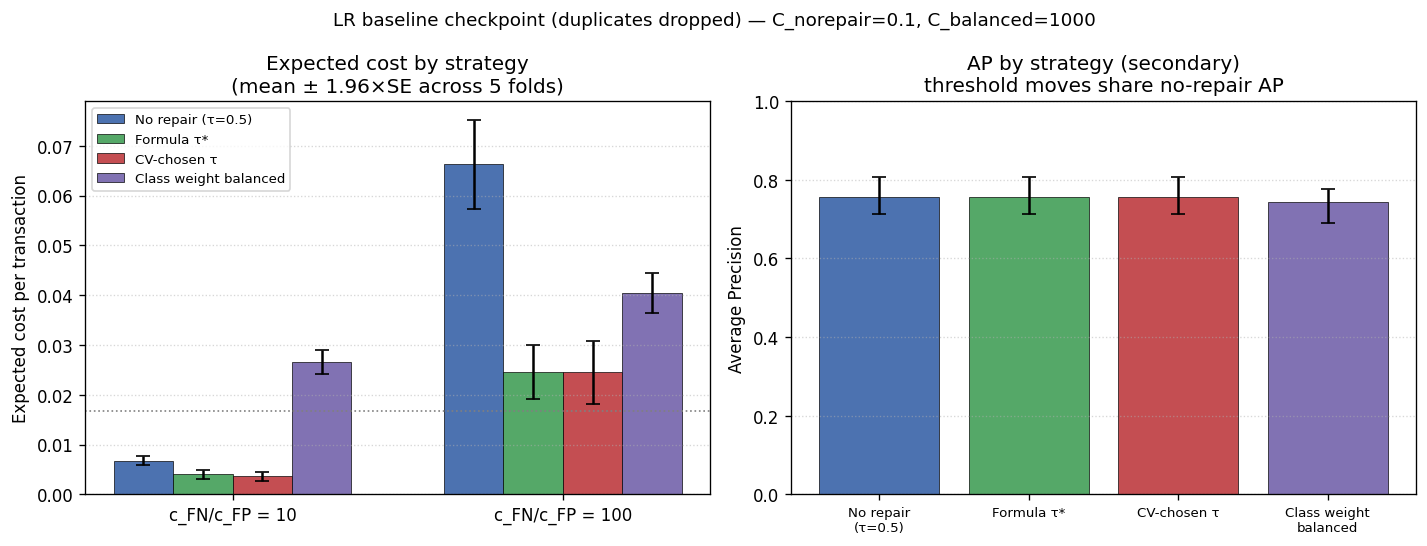

In [8]:
strategy_order = [
    "no_repair_0.5",
    "formula_tau",
    "cv_tau",
    "class_weight_balanced_0.5",
]
labels = {
    "no_repair_0.5": "No repair\n(τ=0.5)",
    "formula_tau": "Formula τ*",
    "cv_tau": "CV-chosen τ",
    "class_weight_balanced_0.5": "Class weight\nbalanced",
}
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B3"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), dpi=120)

x = np.arange(len(COST_RATIOS))
width = 0.18
for i, strat in enumerate(strategy_order):
    sub = result_table[result_table["strategy"] == strat].set_index("ratio").loc[COST_RATIOS]
    means = sub["cost_mean"].to_numpy()
    ses = sub["cost_se"].to_numpy()
    axes[0].bar(
        x + (i - 1.5) * width,
        means,
        width,
        yerr=1.96 * ses,
        capsize=4,
        color=colors[i],
        edgecolor="black",
        linewidth=0.4,
        label=labels[strat].replace("\n", " "),
    )

axes[0].axhline(naive["always_legitimate"]["cost_ratio10"], color="gray", ls=":", lw=1)
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"c_FN/c_FP = {r}" for r in COST_RATIOS])
axes[0].set_ylabel("Expected cost per transaction")
axes[0].set_title("Expected cost by strategy\n(mean ± 1.96×SE across 5 folds)")
axes[0].legend(fontsize=8, loc="upper left")
axes[0].grid(axis="y", linestyle=":", alpha=0.5)

ap_means, ap_mins, ap_maxs, ap_labels = [], [], [], []
for strat in strategy_order:
    s = next(s for s in strategies if s["strategy"] == strat)
    ap_means.append(s["average_precision"]["mean"])
    ap_mins.append(s["average_precision"]["min"])
    ap_maxs.append(s["average_precision"]["max"])
    ap_labels.append(labels[strat])

xpos = np.arange(len(strategy_order))
ap_means = np.array(ap_means)
ap_mins = np.array(ap_mins)
ap_maxs = np.array(ap_maxs)
axes[1].bar(
    xpos,
    ap_means,
    color=colors,
    edgecolor="black",
    linewidth=0.4,
    yerr=[ap_means - ap_mins, ap_maxs - ap_means],
    capsize=4,
)
axes[1].set_xticks(xpos)
axes[1].set_xticklabels(ap_labels, fontsize=8)
axes[1].set_ylabel("Average Precision")
axes[1].set_ylim(0.0, 1.0)
axes[1].set_title("AP by strategy (secondary)\nthreshold moves share no-repair AP")
axes[1].grid(axis="y", linestyle=":", alpha=0.5)

fig.suptitle(
    f"LR baseline checkpoint (duplicates dropped) — C_norepair={best_C:g}, C_balanced={best_C_bal:g}",
    fontsize=11,
)
fig.tight_layout()
fig_path = RESULTS_DIR / "baseline.png"
fig.savefig(fig_path, bbox_inches="tight")
print(f"Saved {fig_path}")
plt.show()

## 8. Save artifacts

In [9]:
results_path = RESULTS_DIR / "baseline_results.json"
folds_path = RESULTS_DIR / "baseline_folds.csv"

best_df.assign(strategy_family="norepair").to_csv(folds_path, index=False)
# append balanced folds
bal_df.assign(strategy_family="balanced").to_csv(
    folds_path, mode="a", header=False, index=False
)

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(f"Saved {results_path}")
print(f"Saved {folds_path}")
print(f"Saved {fig_path}")
print("\nHeadline (mean expected cost, 95% CI from fold SE):")
for s in strategies:
    r10, r100 = s["cost_ratio10"], s["cost_ratio100"]
    print(
        f"  {s['strategy']:28s}  "
        f"r10={r10['mean']:.5f} [{r10['ci95_lo']:.5f},{r10['ci95_hi']:.5f}]  "
        f"r100={r100['mean']:.5f} [{r100['ci95_lo']:.5f},{r100['ci95_hi']:.5f}]  "
        f"AP={s['average_precision']['mean']:.3f}"
    )

Saved .\results\baseline_results.json
Saved .\results\baseline_folds.csv
Saved .\results\baseline.png

Headline (mean expected cost, 95% CI from fold SE):
  no_repair_0.5                 r10=0.00677 [0.00555,0.00799]  r100=0.06625 [0.05361,0.07888]  AP=0.756
  formula_tau                   r10=0.00401 [0.00266,0.00537]  r100=0.02454 [0.01694,0.03214]  AP=0.756
  cv_tau                        r10=0.00360 [0.00235,0.00485]  r100=0.02453 [0.01561,0.03344]  AP=0.756
  class_weight_balanced_0.5     r10=0.02659 [0.02311,0.03007]  r100=0.04047 [0.03475,0.04618]  AP=0.744


## Issues / next steps

- **Duplicates**: this dataset contains exact duplicate rows (see Section 1). We now drop
  them before splitting, which avoids a train/validation/test leakage path. Headline numbers
  shift slightly versus the pre-fix run because of the ~1,100 fewer rows and ~19 fewer frauds.
- **`C` selection is noise-sensitive**: the no-repair AP curve is nearly flat for `C >= 0.1`
  (±0.0005 or so), so the argmax `C` can flip between reruns/package versions. Treat the
  choice of `C` as a tie across `{0.1, 1, 10, 100, 1000}`, not a meaningfully "best" value.
- **CV-chosen τ caveat**: picked on in-sample training-fold probabilities, not a nested split;
  the reported cost itself is still honestly computed on the held-out validation fold.
- Test set still untouched (98 frauds before dedup; recompute after dedup). Bootstrap CIs come
  after all methods are locked.
- Next: `HistGradientBoostingClassifier`, random undersampling inside folds, paired stratified
  test bootstrap, calibration plots.
- One team member submits this checkpoint for the whole group.